# 02. 전처리

Dataset / DataLoader 구성, Resize+Padding, 정규화, Train 전용 증강

## 0. 공통 설정

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # notebooks/ 에서 src/ 를 import 하기 위함

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import ROOT, DATA_DIR, FIG_DIR, RESULT_DIR, CLASS_NAMES, set_seed, setup_korean_font, save_fig

SEED = 42
set_seed(SEED)
setup_korean_font()
print("프로젝트 루트:", ROOT)

프로젝트 루트: /Users/adj/Team_Project


## 1. CSV 기반 Dataset

In [8]:
# src/data.py를 고치면 커널 재시작 없이 바로 반영되게 하는 설정
%load_ext autoreload
%autoreload 2

import time
import torch
from PIL import Image
from src.data import (PadToSquare, get_transform, FashionDataset, get_loaders, load_meta,
                      IMAGENET_MEAN, IMAGENET_STD)

meta = load_meta()
order = ["dress", "jacket", "pants", "skirt", "top"]
ko = dict(zip(order, CLASS_NAMES))
train_df = meta[meta["split"] == "train"].reset_index(drop=True)
print("전체:", len(meta), "/ Train:", len(train_df))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
전체: 12842 / Train: 8523


In [4]:
ds = FashionDataset(train_df, get_transform(train=True))
x, y = ds[0]
print("데이터셋 크기:", len(ds))
print("이미지 텐서 모양:", tuple(x.shape), x.dtype)      # (3, 224, 224) 기대
print("정답:", y, CLASS_NAMES[y])
print("값 범위:", round(x.min().item(), 2), "~", round(x.max().item(), 2))

데이터셋 크기: 8523
이미지 텐서 모양: (3, 224, 224) torch.float32
정답: 1 재킷
값 범위: -1.88 ~ 2.64


## 2. Transform (Resize + Padding, 정규화)

(다음 단계에서 작성)

저장됨: figures/02_padding_vs_stretch.png


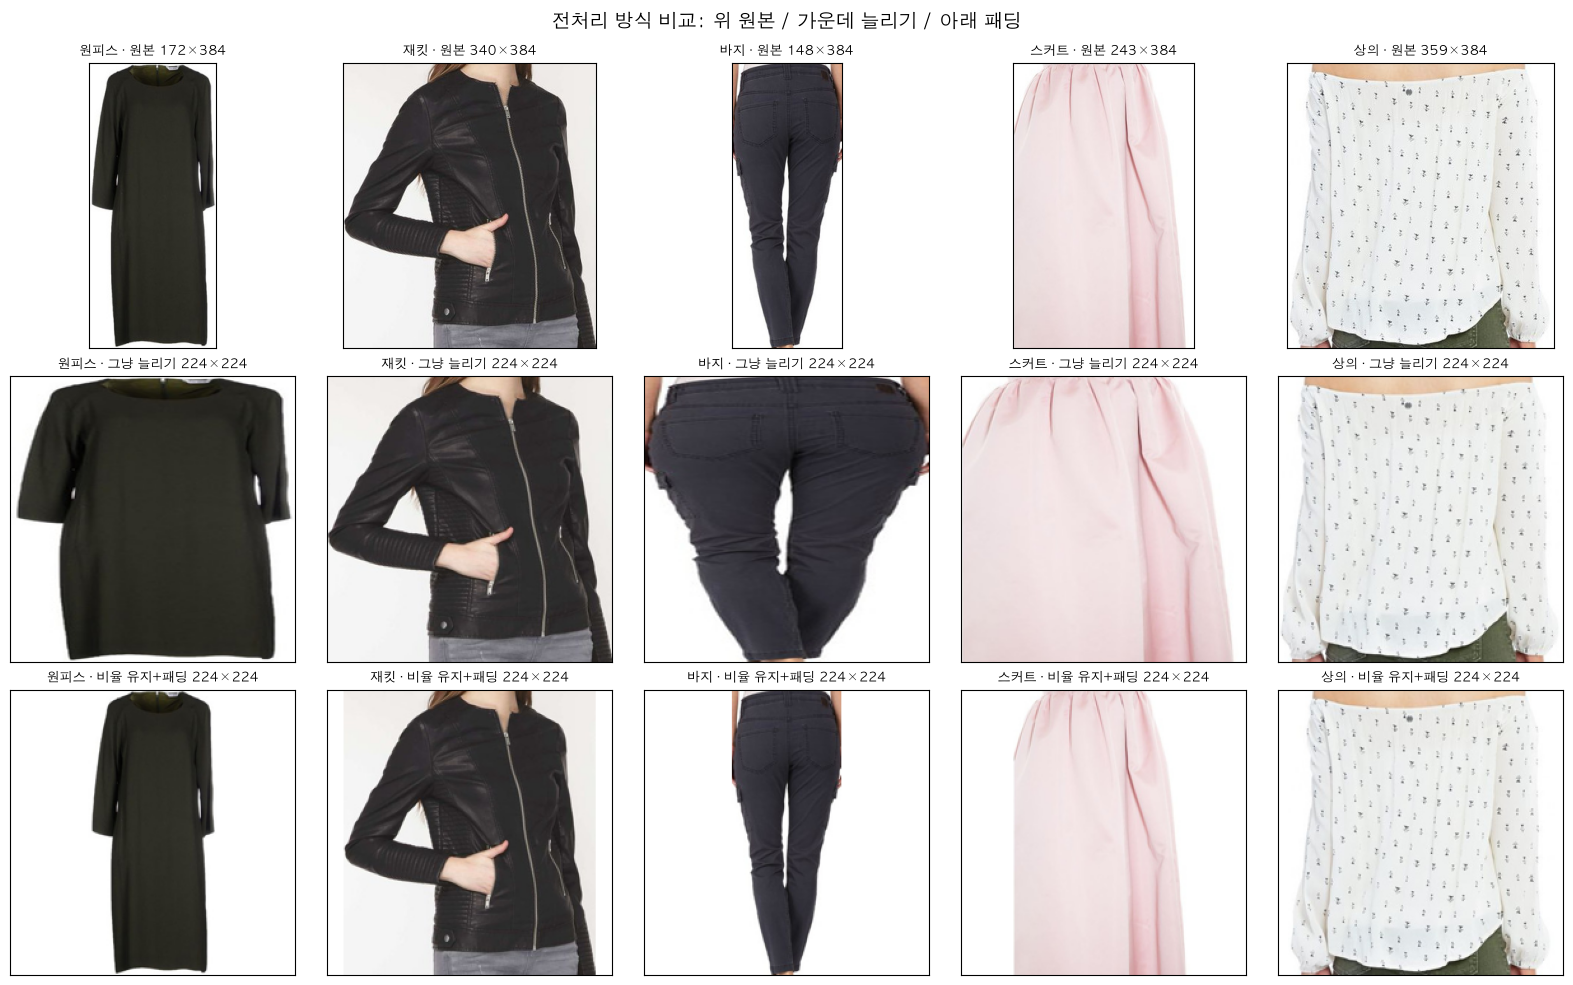

In [5]:
pad = PadToSquare()
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for i, cat in enumerate(order):
    row = train_df[train_df["category"] == cat].sample(1, random_state=SEED).iloc[0]
    img = Image.open(DATA_DIR / row["image_path"]).convert("RGB")
    views = [(img, f"원본 {img.width}×{img.height}"),
             (img.resize((224, 224)), "그냥 늘리기 224×224"),
             (pad(img), "비율 유지+패딩 224×224")]
    for r, (v, title) in enumerate(views):
        axes[r, i].imshow(v)
        axes[r, i].set_title(f"{ko[cat]} · {title}", fontsize=9)
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])   # 테두리는 남겨서 패딩 영역이 보이게
plt.suptitle("전처리 방식 비교: 위 원본 / 가운데 늘리기 / 아래 패딩", fontsize=14)
plt.tight_layout()
save_fig("02_padding_vs_stretch")
plt.show()

## 3. DataLoader 및 배치 확인

In [6]:
loaders = get_loaders(batch_size=32)
for split, ld in loaders.items():
    print(f"{split}: {len(ld.dataset):,}장 / {len(ld)}배치")

xb, yb = next(iter(loaders["train"]))
print("\n배치 모양:", tuple(xb.shape), "/ 정답 모양:", tuple(yb.shape))
print("첫 배치 클래스 분포:", torch.bincount(yb, minlength=5).tolist())

# 이미지 읽기·변환에 걸리는 시간 (모델 계산 제외)
start = time.time()
for i, _ in enumerate(loaders["train"]):
    if i == 49:
        break
elapsed = time.time() - start
print(f"\n50배치 로딩: {elapsed:.1f}초 → Train 1 epoch 로딩만 약 {elapsed / 50 * len(loaders['train']):.0f}초 예상")

train: 8,523장 / 267배치
val: 1,722장 / 54배치
test: 2,597장 / 82배치

배치 모양: (32, 3, 224, 224) / 정답 모양: (32,)
첫 배치 클래스 분포: [7, 9, 8, 4, 4]

50배치 로딩: 3.8초 → Train 1 epoch 로딩만 약 20초 예상


저장됨: figures/02_batch_check.png


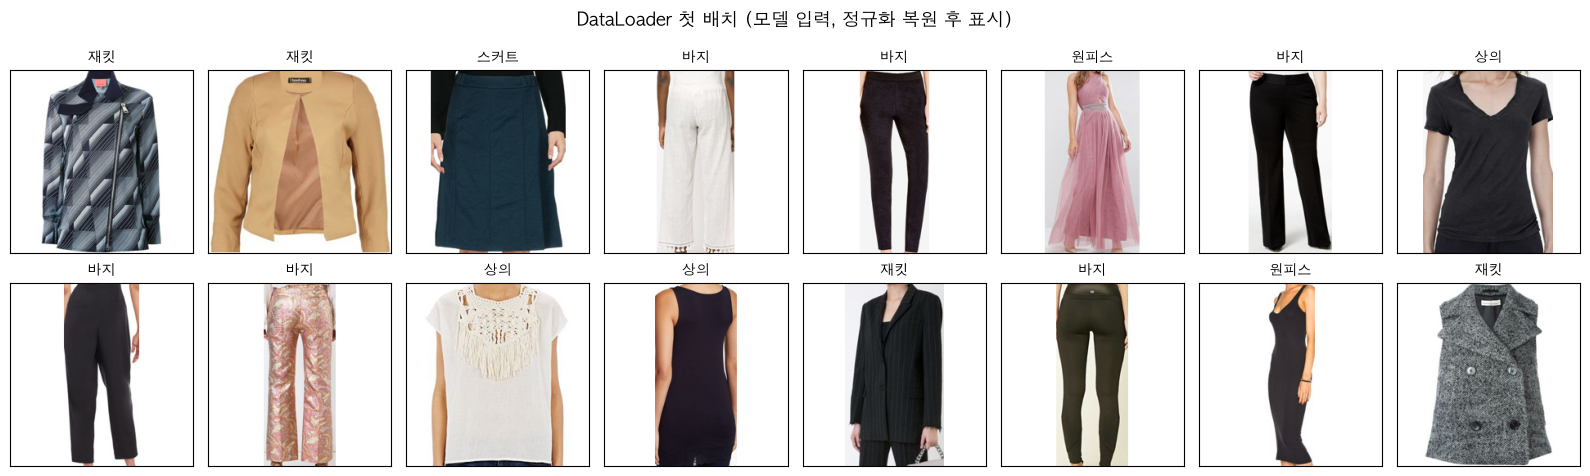

In [7]:
# 정규화를 되돌려서 눈으로 볼 수 있게 표시
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

xb, yb = next(iter(loaders["train"]))
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, img, lab in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1))   # (3,H,W) → (H,W,3)
    ax.set_title(CLASS_NAMES[lab], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("DataLoader 첫 배치 (모델 입력, 정규화 복원 후 표시)", fontsize=13)
plt.tight_layout()
save_fig("02_batch_check")
plt.show()

### 전처리 정리
- Dataset: metadata.csv 기반 (클래스 폴더 없음). 입력은 이미지 픽셀만, 정답은 target_id만 사용
- 크기: 비율 유지 축소 + 흰색 패딩으로 224×224 (3단계: 클래스별 비율 차이 보존, 배경이 흰색)
- 정규화: ImageNet 평균·표준편차, 네 전략 모두 동일 적용 (교안: 초기 비교 조건 통일)
- 증강: 기본 비교에서는 미적용, 12단계 개선 실험 후보로 남김 (적용 시 Train에만)
- 분할: 제공된 train/val/test 그대로 사용 (2단계: 상품 단위 누수 없음 확인)
- DataLoader: Batch 32, Train만 셔플(시드 고정) → Train 267 / Val 54 / Test 82 배치
- Train 1 epoch 이미지 로딩 시간: 약 20초 (모델 계산 제외, num_workers=0으로 충분)
- 늘리기 vs 패딩 비교: 세로로 긴 원피스(172×384)·바지(148×384)는 늘리면 각각 짧은 상의·통 넓은 바지처럼 변형됨,
  정사각형에 가까운 재킷·상의는 차이 거의 없음 → 패딩의 효과는 모양 단서가 중요한 세로형 클래스에 집중